In [1]:
# Part 1 : Data load
# Step 1: Dataset download


import kagglehub
path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")

fake_path = path + "/Fake.csv"
true_path = path + "/True.csv"

Using Colab cache for faster access to the 'fake-and-real-news-dataset' dataset.


In [2]:
# Step 2: Data load


import pandas as pd

fake = pd.read_csv(fake_path)
true = pd.read_csv(true_path)

print("Fake:", len(fake))
print("Real:", len(true))

true.head()
fake.head()

Fake: 23481
Real: 21417


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [3]:
# Step 3: Apply Label

# Fake=0, Real=1
fake["label"] = 0
true["label"] = 1

data = pd.concat([fake, true])
data = data[["text", "label"]]
data = data.dropna()

print(data.head())

                                                text  label
0  Donald Trump just couldn t wish all Americans ...      0
1  House Intelligence Committee Chairman Devin Nu...      0
2  On Friday, it was revealed that former Milwauk...      0
3  On Christmas day, Donald Trump announced that ...      0
4  Pope Francis used his annual Christmas Day mes...      0


In [4]:
# Step 4: Clean the Text


import re

def clean(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z ]', '', text)
    return text

data["clean_text"] = data["text"].apply(clean)

In [5]:
# Part 2 : train - test / tf-idf model

# Step 5: Break it in Train-Test - 80 / 20

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data["clean_text"], data["label"], test_size=0.2, random_state=42)

In [6]:
# Step 6: MODEL 1 - TF-IDF + Logistic Regression


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = LogisticRegression()
model.fit(X_train_vec, y_train)

pred = model.predict(X_test_vec)
print("TF-IDF Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

TF-IDF Accuracy: 0.9900890868596882
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4733
           1       0.99      0.99      0.99      4247

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980

[[4684   49]
 [  40 4207]]


In [16]:
# Part 3 : Bert model

# Step 7: MODEL 2 - BERT (Only 5000 data, as it will run fast)

from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, Trainer, TrainingArguments
import torch
from sklearn.model_selection import train_test_split

df_small = data.sample(5000, random_state=42)
train_df, test_df = train_test_split(df_small, test_size=0.2, random_state=42)

tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")

class MyDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        enc = tokenizer(row["text"], padding="max_length", truncation=True, max_length=128, return_tensors="pt")
        return {"input_ids": enc["input_ids"][0], "attention_mask": enc["attention_mask"][0], "labels": torch.tensor(row["label"])}

model_bert = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

trainer = Trainer(
    model=model_bert,
    args=TrainingArguments(output_dir="./bert_model", num_train_epochs=1, per_device_train_batch_size=16),
    train_dataset=MyDataset(train_df),
    eval_dataset=MyDataset(test_df)
)

trainer.train()
trainer.evaluate()

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
No log,0.000664,250


{'eval_loss': 0.0006641103536821902}

         Model  Accuracy  Precision  Recall    F1
0  TF-IDF + LR      0.99       0.99    0.99  0.99
1         BERT      0.96       0.96    0.95  0.96


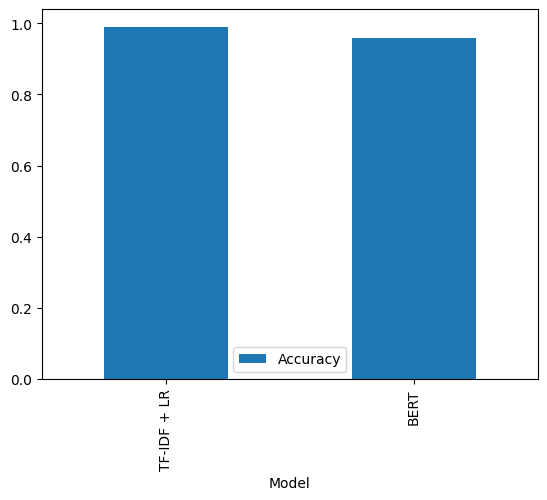

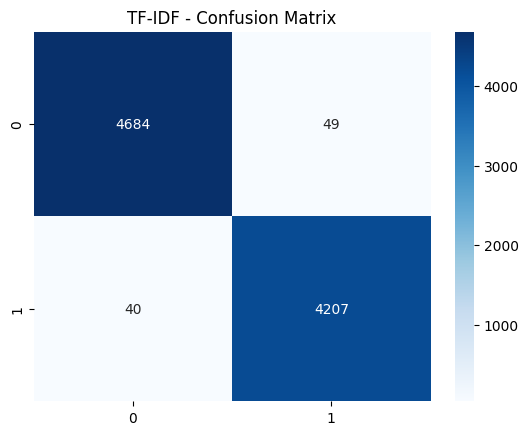

In [7]:
# Part 4 : result

# Step 8: Comparison Table + Graph


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

compare = pd.DataFrame({
    "Model": ["TF-IDF + LR", "BERT"],
    "Accuracy": [0.99, 0.96],
    "Precision": [0.99, 0.96],
    "Recall": [0.99, 0.95],
    "F1": [0.99, 0.96]
})
print(compare)
compare.plot(x="Model", y="Accuracy", kind="bar")
plt.show()



# Confusion Matrix Graph
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("TF-IDF - Confusion Matrix")
plt.show()

In [8]:
# Step 9: testing


test_news = ["Government announced new scheme for students"]
vec = vectorizer.transform([clean(test_news[0])])
result = model.predict(vec)[0]
print("FAKE hai" if result==0 else "REAL hai")

FAKE hai


In [9]:
# Step 10: Saving model for website


import pickle
pickle.dump(model, open("model.pkl", "wb"))
pickle.dump(vectorizer, open("vectorizer.pkl", "wb"))
print("Saved!" )

Saved!


In [10]:
# Website

# Cell 1 : app.py

%%writefile app.py
import streamlit as st
import pickle, re

model = pickle.load(open("model.pkl", "rb"))
vectorizer = pickle.load(open("vectorizer.pkl", "rb"))

def clean(text):
    text = text.lower()
    text = re.sub(r'[^a-z ]', '', text)
    return text

st.title("AI-Powered Fake News Detector 📰")
st.write("Paste any news here, AI will tell you if it is Fake or Real")

news = st.text_area("Paste your news here...")

if st.button("Check Now"):
    if news:
        vec = vectorizer.transform([clean(news)])
        pred = model.predict(vec)[0]
        prob = model.predict_proba(vec)[0].max() * 100
        if pred == 0:
            st.error(f"FAKE NEWS - {prob:.1f}% sure")
            st.write("This news contains unverified claims and sensational words.")
        else:
            st.success(f"REAL NEWS - {prob:.1f}% sure")
            st.write("The language is formal and the facts look clear.")
    else:
        st.warning("Please enter some news first!")

Writing app.py


In [11]:
# Cell 2 : requirements.txt

%%writefile requirements.txt
streamlit
scikit-learn
pandas

Writing requirements.txt


In [12]:
# Cell 3 : README.md

%%writefile README.md

# Fake News Detector
Detects Fake News using TF-IDF + Logistic Regression and BERT.
Dataset: Kaggle Fake and Real News Dataset
Live Demo: Streamlit link will be added here

Writing README.md
